In [1]:

# SECTION 1: IMPORT LIBRARIES AND SET PROJECT PATHS

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix

# Project directory
PROJECT_DIR = r"C:\Users\DELL\Documents\EcoSort-AI"

# Dataset directories
DATA_DIR = os.path.join(PROJECT_DIR, "data")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VALIDATION_DIR = os.path.join(DATA_DIR, "validation")
TEST_DIR = os.path.join(DATA_DIR, "test")

# Model directory
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Check TensorFlow version
print("TensorFlow Version:", tf.__version__)

# Check dataset folders
print("\nChecking dataset folders:")

for folder in [TRAIN_DIR, VALIDATION_DIR, TEST_DIR]:
    print(folder, "->", os.path.exists(folder))

print("\nModel directory:", MODEL_DIR)
print("Setup completed successfully!")


TensorFlow Version: 2.18.0

Checking dataset folders:
C:\Users\DELL\Documents\EcoSort-AI\data\train -> True
C:\Users\DELL\Documents\EcoSort-AI\data\validation -> True
C:\Users\DELL\Documents\EcoSort-AI\data\test -> True

Model directory: C:\Users\DELL\Documents\EcoSort-AI\models
Setup completed successfully!


In [2]:
# Define dataset location
TRAIN_DIR = r"C:\Users\DELL\Documents\EcoSort-AI\data\train"

# Load training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(256, 256),
    batch_size=32,
    label_mode="int",
    shuffle=True,
    seed=42
)

Found 8581 files belonging to 10 classes.


In [3]:
import os

PROJECT_DIR = r"C:\Users\DELL\Documents\EcoSort-AI"

TRAIN_DIR = os.path.join(PROJECT_DIR, "data", "train")

print("Training folder:", TRAIN_DIR)
print("Folder exists:", os.path.exists(TRAIN_DIR))

Training folder: C:\Users\DELL\Documents\EcoSort-AI\data\train
Folder exists: True


In [4]:
import os

print("Folders inside training directory:\n")

for folder in sorted(os.listdir(TRAIN_DIR)):
    folder_path = os.path.join(TRAIN_DIR, folder)

    if os.path.isdir(folder_path):
        print(folder)

Folders inside training directory:

battery
biological
cardboard
clothes
glass
metal
paper
plastic
shoes
trash


In [5]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(256, 256),
    batch_size=32,
    label_mode="int",
    shuffle=True,
    seed=42
)

print("Class names:", train_dataset.class_names)
print("Total classes:", len(train_dataset.class_names))

Found 8581 files belonging to 10 classes.
Class names: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Total classes: 10


In [6]:

# Load validation images

VALIDATION_DIR = os.path.join(DATA_DIR, "validation")

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    VALIDATION_DIR,
    image_size=(256, 256),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("Validation dataset loaded successfully!")


Found 1839 files belonging to 10 classes.
Validation dataset loaded successfully!


In [7]:

# Load testing images

TEST_DIR = os.path.join(DATA_DIR, "test")

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(256, 256),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("Testing dataset loaded successfully!")


Found 1839 files belonging to 10 classes.
Testing dataset loaded successfully!


In [8]:
# Count images in each dataset
train_count = len(train_dataset.file_paths)
validation_count = len(validation_dataset.file_paths)
test_count = len(test_dataset.file_paths)

print("Training Images:", train_count)
print("Validation Images:", validation_count)
print("Testing Images:", test_count)

print("-------------------------")
print("Total Images:", train_count + validation_count + test_count)

Training Images: 8581
Validation Images: 1839
Testing Images: 1839
-------------------------
Total Images: 12259


In [9]:

# Check class names in all datasets

class_names = train_dataset.class_names

print("Number of classes:", len(class_names))
print("Waste categories:", class_names)

print("\nChecking class consistency:")

print("Training:", train_dataset.class_names)
print("Validation:", validation_dataset.class_names)
print("Testing:", test_dataset.class_names)

assert train_dataset.class_names == validation_dataset.class_names
assert train_dataset.class_names == test_dataset.class_names

print("\nAll datasets have matching classes!")


Number of classes: 10
Waste categories: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']

Checking class consistency:
Training: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Validation: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Testing: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']

All datasets have matching classes!


In [10]:

# Check image and label dimensions

for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())


Image batch shape: (32, 256, 256, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


## 5. Visualizing Sample Waste Images

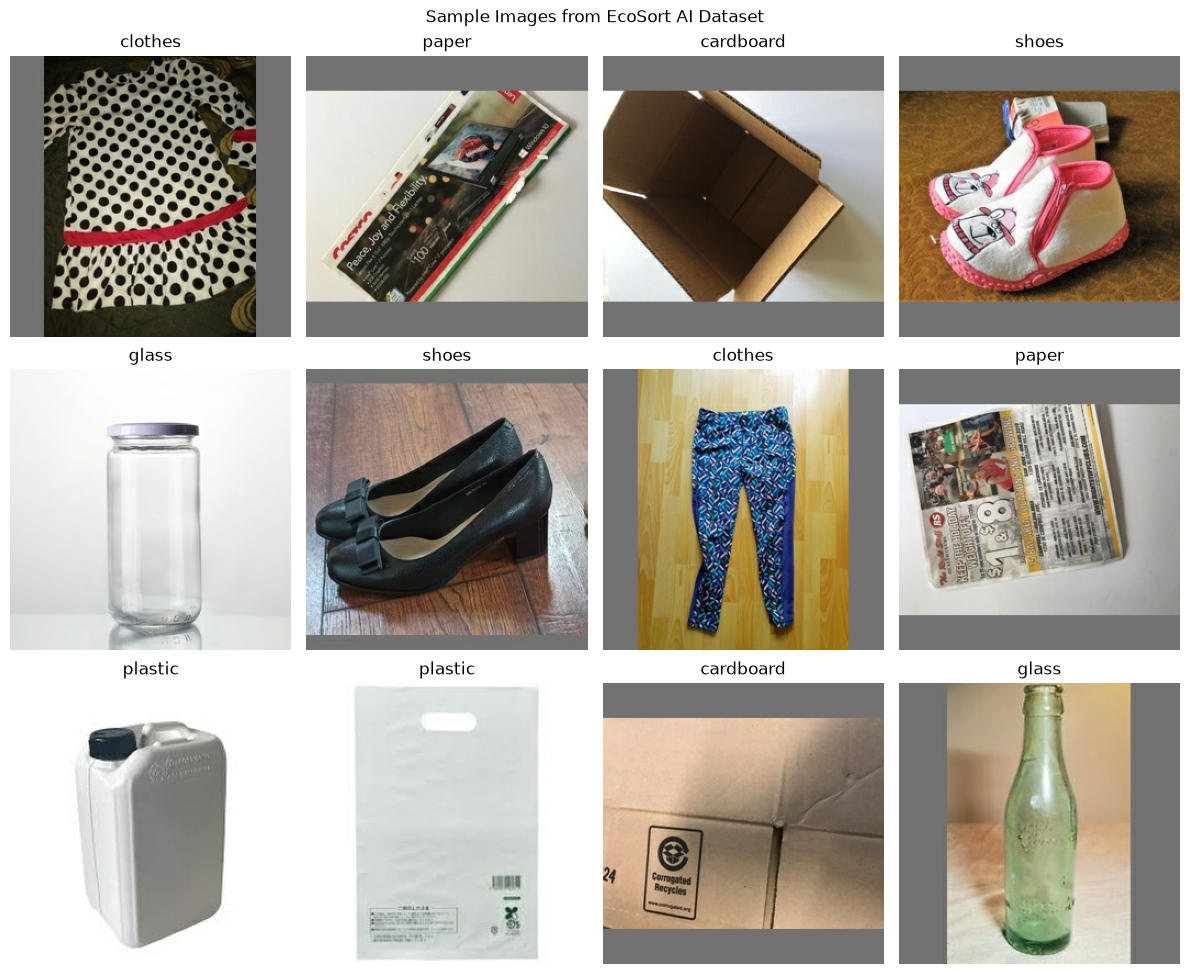

In [11]:

# Display sample images from the training dataset

plt.figure(figsize=(12, 10))

for images, labels in train_dataset.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = int(labels[i].numpy())
        plt.title(class_names[label_index])

        plt.axis("off")

plt.suptitle("Sample Images from EcoSort AI Dataset")
plt.tight_layout()
plt.show()


## 6. Image Augmentation

In [12]:

# Define image augmentation layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

print("Image augmentation pipeline created successfully!")


Image augmentation pipeline created successfully!


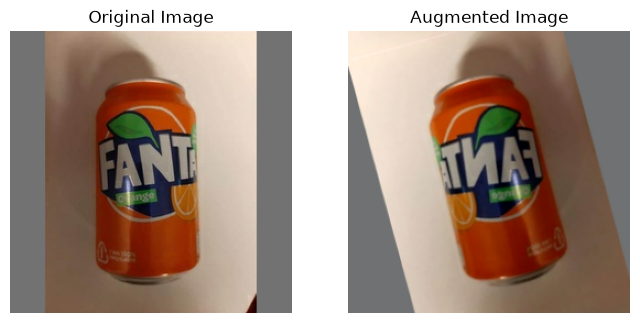

Image augmentation tested successfully!


In [13]:

# Display original and augmented images

for images, labels in train_dataset.take(1):

    sample_image = images[0]

    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(sample_image.numpy().astype("uint8"))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        tf.clip_by_value(augmented_image, 0, 255).numpy().astype("uint8")
    )
    plt.title("Augmented Image")
    plt.axis("off")

    plt.show()

print("Image augmentation tested successfully!")


## 8. Building Basic CNN Model

In [15]:

# Build Basic CNN model

cnn_model = models.Sequential([

    # Input layer
    layers.Input(shape=(256, 256, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # Apply data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Convert feature maps into one dimension
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),

    # Prevent overfitting
    layers.Dropout(0.5),

    # Output layer for 10 categories
    layers.Dense(10, activation="softmax")
])

# Display model architecture
cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ rescaling (Rescaling)     │ (None, 256, 256,   │          0 │
│                           │ 3)                 │            │
├───────────────────────────┼────────────────────┼────────────┤
│ sequential (Sequential)   │ (None, 256, 256,   │          0 │
│                           │ 3)                 │            │
├───────────────────────────┼────────────────────┼────────────┤
│ conv2d (Conv2D)           │ (None, 254, 254,   │        896 │
│                           │ 32)                │            │
├───────────────────────────┼────────────────────┼────────────┤
│ max_pooling2d             │ (None, 127, 127,   │          0 │
│ (MaxPooling2D)            │ 32)                │            │
├───────────────────────────┼────────────────────┼────────────┤
│ conv2d_1 (Conv2D)         │ (None, 125, 125,   │     18,496 │
│                           │ 64)                │            │
├───────────────────────────┼────────────────────┼────────────┤
│ max_pooling2d_1           │ (None, 62, 62, 64) │          0 │
│ (MaxPooling2D)            │                    │            │
├───────────────────────────┼────────────────────┼────────────┤
│ conv2d_2 (Conv2D)         │ (None, 60, 60,     │     73,856 │
│                           │ 128)               │            │
├───────────────────────────┼────────────────────┼────────────┤
│ max_pooling2d_2           │ (None, 30, 30,     │          0 │
│ (MaxPooling2D)            │ 128)               │            │
├───────────────────────────┼────────────────────┼────────────┤
│ flatten (Flatten)         │ (None, 115200)     │          0 │
├───────────────────────────┼────────────────────┼────────────┤
│ dense (Dense)             │ (None, 128)        │ 14,745,728 │
├───────────────────────────┼────────────────────┼────────────┤
│ dropout (Dropout)         │ (None, 128)        │          0 │
├───────────────────────────┼────────────────────┼────────────┤
│ dense_1 (Dense)           │ (None, 10)         │      1,290 │
└───────────────────────────┴────────────────────┴────────────┘

 Total params: 14,840,266 (56.61 MB)

 Trainable params: 14,840,266 (56.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:

# Compile CNN model

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


## 9. Training Basic CNN Model

In [17]:

# Train CNN model

cnn_history = cnn_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15
)


Epoch 1/15


C:\Users\DELL\Documents\EcoSort-AI\.venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


269/269 ━━━━━━━━━━━━━━━━━━━━ 190s 697ms/step - accuracy: 0.2695 - loss: 2.0587 - val_accuracy: 0.4046 - val_loss: 1.7398
Epoch 2/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 186s 691ms/step - accuracy: 0.3801 - loss: 1.7566 - val_accuracy: 0.4959 - val_loss: 1.4528
Epoch 3/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 192s 713ms/step - accuracy: 0.4355 - loss: 1.6247 - val_accuracy: 0.5182 - val_loss: 1.4307
Epoch 4/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 151s 560ms/step - accuracy: 0.4586 - loss: 1.5549 - val_accuracy: 0.5432 - val_loss: 1.3371
Epoch 5/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 158s 589ms/step - accuracy: 0.4862 - loss: 1.4844 - val_accuracy: 0.5530 - val_loss: 1.2752
Epoch 6/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 166s 615ms/step - accuracy: 0.4934 - loss: 1.4440 - val_accuracy: 0.5889 - val_loss: 1.2402
Epoch 7/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 158s 586ms/step - accuracy: 0.5179 - loss: 1.3914 - val_accuracy: 0.5726 - val_loss: 1.2427
Epoch 8/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 161s 598ms/step - accuracy: 0.5281 - loss: 1.37

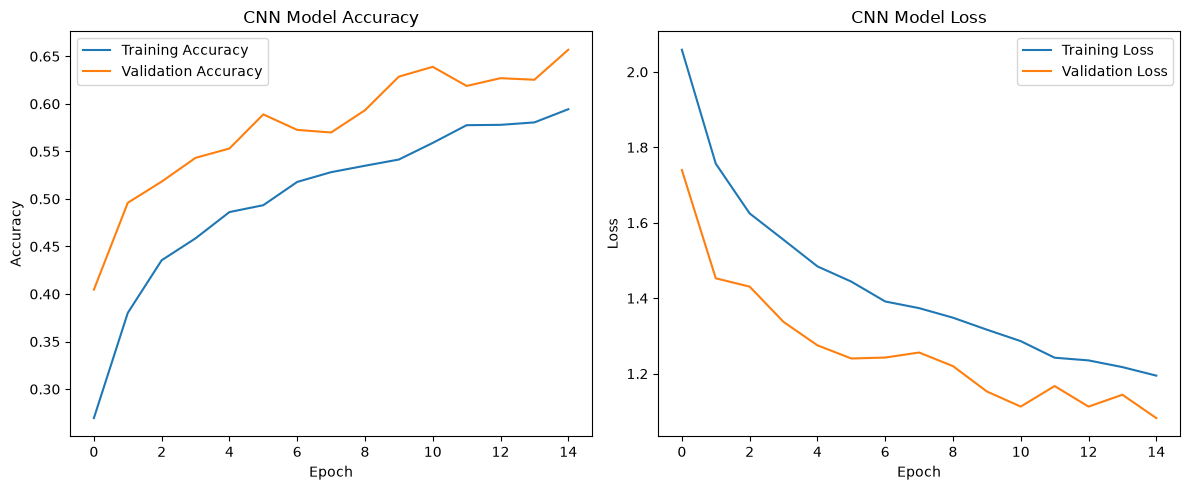

In [18]:

# Plot CNN training performance

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [19]:
# Evaluate CNN model on test dataset

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(test_dataset)

print("CNN Test Accuracy:", round(cnn_test_accuracy * 100, 2), "%")
print("CNN Test Loss:", round(cnn_test_loss, 4))

58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 126ms/step - accuracy: 0.6433 - loss: 1.0978
CNN Test Accuracy: 64.33 %
CNN Test Loss: 1.0978


## MobileNetV2 – Transfer Learning

In [20]:
# Build MobileNetV2 model using transfer learning

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load pre-trained MobileNetV2
base_model = MobileNetV2(
    input_shape=(256, 256, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pre-trained layers
base_model.trainable = False

# Create the complete model
inputs = layers.Input(shape=(256, 256, 3))

# Apply data augmentation
x = data_augmentation(inputs)

# Apply MobileNetV2 preprocessing
x = preprocess_input(x)

# Extract image features
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

# Final model
mobilenet_model = models.Model(inputs, outputs)

# Compile the model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
mobilenet_model.summary()

C:\Users\DELL\AppData\Local\Temp\ipykernel_13036\256452280.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape       ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ input_layer_3             │ (None, 256, 256,   │          0 │
│ (InputLayer)              │ 3)                 │            │
├───────────────────────────┼────────────────────┼────────────┤
│ sequential (Sequential)   │ (None, 256, 256,   │          0 │
│                           │ 3)                 │            │
├───────────────────────────┼────────────────────┼────────────┤
│ true_divide (TrueDivide)  │ (None, 256, 256,   │          0 │
│                           │ 3)                 │            │
├───────────────────────────┼────────────────────┼────────────┤
│ subtract (Subtract)       │ (None, 256, 256,   │          0 │
│                           │ 3)                 │            │
├───────────────────────────┼────────────────────┼────────────┤
│ mobilenetv2_1.00_224      │ (None, 8, 8, 1280) │  2,257,984 │
│ (Functional)              │                    │            │
├───────────────────────────┼────────────────────┼────────────┤
│ global_average_pooling2d  │ (None, 1280)       │          0 │
│ (GlobalAveragePooling2D)  │                    │            │
├───────────────────────────┼────────────────────┼────────────┤
│ dropout_1 (Dropout)       │ (None, 1280)       │          0 │
├───────────────────────────┼────────────────────┼────────────┤
│ dense_2 (Dense)           │ (None, 10)         │     12,810 │
└───────────────────────────┴────────────────────┴────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Training MobileNetV2 – Stage 1

In [22]:
# Train MobileNetV2 model

mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 174s 647ms/step - accuracy: 0.8468 - loss: 0.4801 - val_accuracy: 0.8711 - val_loss: 0.3929
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 166s 616ms/step - accuracy: 0.8496 - loss: 0.4630 - val_accuracy: 0.8717 - val_loss: 0.3841
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 161s 599ms/step - accuracy: 0.8592 - loss: 0.4437 - val_accuracy: 0.8728 - val_loss: 0.3730
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 161s 598ms/step - accuracy: 0.8598 - loss: 0.4367 - val_accuracy: 0.8722 - val_loss: 0.3732
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 161s 600ms/step - accuracy: 0.8557 - loss: 0.4339 - val_accuracy: 0.8777 - val_loss: 0.3621
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 164s 610ms/step - accuracy: 0.8610 - loss: 0.4259 - val_accuracy: 0.8809 - val_loss: 0.3589
Epoch 7/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 161s 597ms/step - accuracy: 0.8648 - loss: 0.4049 - val_accuracy: 0.8842 - val_loss: 0.3503
Epoch 8/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 160s 595ms/step - accuracy: 0.8677 -

### MobileNetV2 – Stage 2: Fine-Tuning

In [23]:
# Unfreeze the MobileNetV2 base model

base_model.trainable = True

# Freeze the first 100 layers
for layer in base_model.layers[:100]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very low learning rate
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Check trainable and non-trainable parameters
print("Trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in mobilenet_model.trainable_weights
))

print("Non-trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in mobilenet_model.non_trainable_weights
))

Trainable parameters: 1852426
Non-trainable parameters: 418368


In [24]:
# Fine-tune MobileNetV2

mobilenet_history_finetune = mobilenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5
)

Epoch 1/5
269/269 ━━━━━━━━━━━━━━━━━━━━ 198s 717ms/step - accuracy: 0.8755 - loss: 0.3673 - val_accuracy: 0.8864 - val_loss: 0.3191
Epoch 2/5
269/269 ━━━━━━━━━━━━━━━━━━━━ 192s 714ms/step - accuracy: 0.8907 - loss: 0.3308 - val_accuracy: 0.8929 - val_loss: 0.3080
Epoch 3/5
269/269 ━━━━━━━━━━━━━━━━━━━━ 195s 725ms/step - accuracy: 0.9042 - loss: 0.2878 - val_accuracy: 0.9032 - val_loss: 0.2689
Epoch 4/5
269/269 ━━━━━━━━━━━━━━━━━━━━ 203s 756ms/step - accuracy: 0.9128 - loss: 0.2586 - val_accuracy: 0.9114 - val_loss: 0.2585
Epoch 5/5
269/269 ━━━━━━━━━━━━━━━━━━━━ 202s 751ms/step - accuracy: 0.9191 - loss: 0.2422 - val_accuracy: 0.9125 - val_loss: 0.2531


## Final MobileNetV2 Model Evaluation

In [25]:
# Evaluate final MobileNetV2 model

mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    test_dataset
)

print("MobileNetV2 Test Accuracy:",
      round(mobilenet_test_accuracy * 100, 2), "%")

print("MobileNetV2 Test Loss:",
      round(mobilenet_test_loss, 4))

58/58 ━━━━━━━━━━━━━━━━━━━━ 30s 509ms/step - accuracy: 0.9076 - loss: 0.2807
MobileNetV2 Test Accuracy: 90.76 %
MobileNetV2 Test Loss: 0.2807


## Classification Report and Confusion Matrix

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     battery       0.97      0.91      0.94       113
  biological       0.98      0.95      0.97       105
   cardboard       0.92      0.85      0.89       211
     clothes       0.99      0.99      0.99       284
       glass       0.86      0.90      0.88       261
       metal       0.85      0.86      0.85       140
       paper       0.84      0.90      0.87       200
     plastic       0.82      0.86      0.84       240
       shoes       0.98      0.99      0.98       217
       trash       0.94      0.75      0.84        68

    accuracy                           0.91      1839
   macro avg       0.92      0.90      0.90      1839
weighted avg       0.91      0.91      0.91      1839



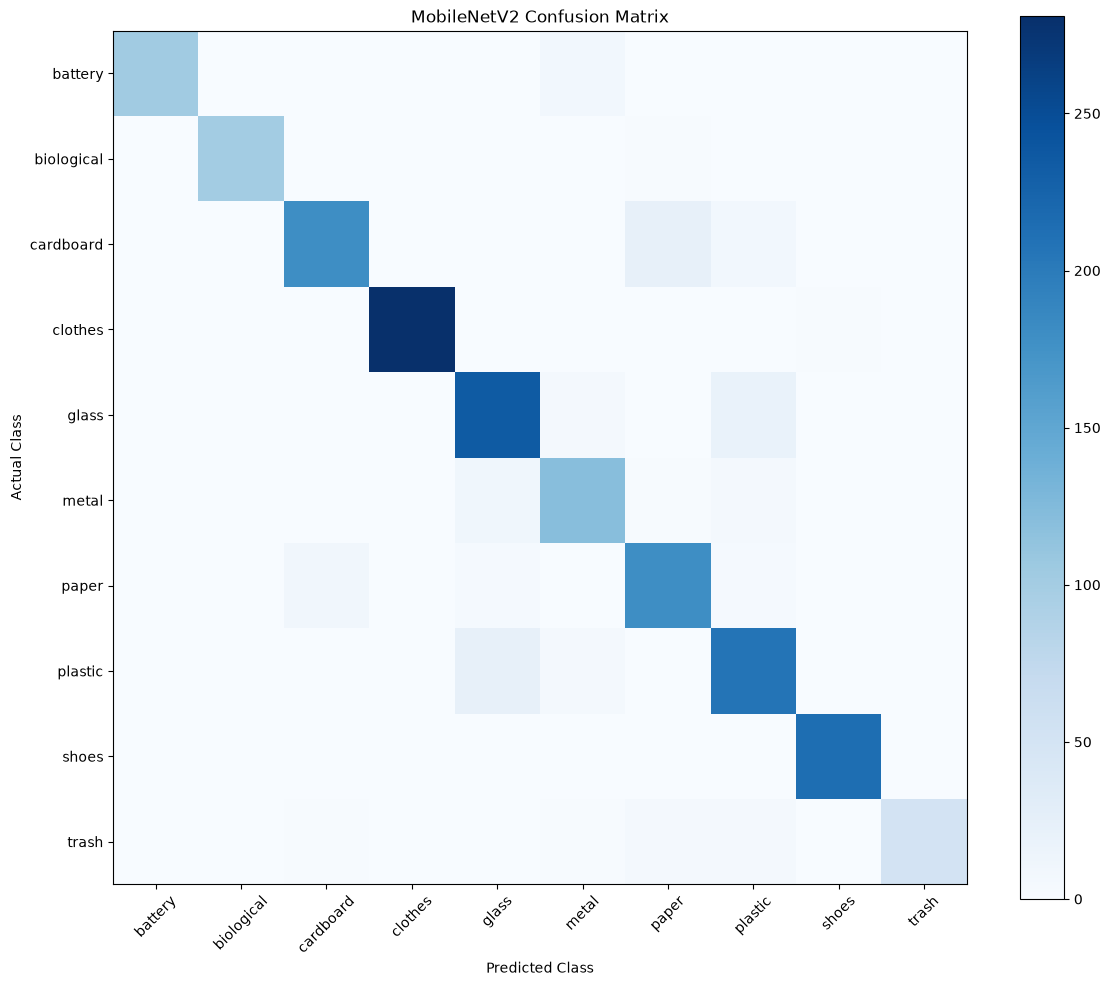

In [27]:
# Generate predictions on test dataset

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = mobilenet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

# Classification report
print("CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

plt.imshow(cm, cmap="Blues")
plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45
)

plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

plt.colorbar()
plt.tight_layout()
plt.show()

## Save Final MobileNetV2 Model

In [28]:
# Save the trained MobileNetV2 model

model_path = os.path.join(
    MODEL_DIR,
    "EcoSort_AI_MobileNetV2_90.keras"
)

mobilenet_model.save(model_path)

# Save class names in the correct order
class_names_path = os.path.join(
    MODEL_DIR,
    "class_names.json"
)

with open(class_names_path, "w") as file:
    json.dump(class_names, file, indent=4)

print("Model saved successfully!")
print("Model path:", model_path)

print("Class names saved successfully!")
print("Class names:", class_names)

Model saved successfully!
Model path: C:\Users\DELL\Documents\EcoSort-AI\models\EcoSort_AI_MobileNetV2_90.keras
Class names saved successfully!
Class names: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
